# Model experiments and local MLflow

Six controlled classifiers use the shared chronological training and validation windows. This notebook reads saved aggregate experiment results. It never trains a separate pipeline or loads final test/replay. SQLite run metadata and fitted models stay in ignored local artifacts.

## Load the recorded experiment

Run `uv run --locked python -m scripts.verify_lesson5` to create independent local batches, then export a batch with `python -m src.experiment_report <batch>`. This notebook displays the committed/shareable aggregate snapshot; model fitting lives in `src.experiments`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd()
if not (root / "reports/lesson5_experiments.json").exists():
    root = root.parent
sys.path.insert(0, str(root))
from src.experiment_report import comparison_table  # noqa: E402

summary = json.loads((root / "reports/lesson5_experiments.json").read_text(encoding="utf-8"))
assert not summary["provenance"]["final_test_evaluated"]
assert not summary["provenance"]["replay_evaluated"]

## Provenance and parameters

MLflow stores one run per candidate, with parameters, metrics, fitted Pipeline, dependency lock, configuration, plots, data hash, split hashes, seed and Git revision. The fixed protocol was saved before the first fit. All preprocessors fit only on train; `duration` is excluded.

In [2]:
provenance = summary["provenance"]
display(
    pd.Series(
        {
            key: provenance[key]
            for key in [
                "git_sha",
                "working_tree_dirty",
                "raw_sha256",
                "seed",
                "rows",
                "dependencies",
            ]
        },
        name="recorded provenance",
    ).to_frame()
)
display(pd.DataFrame(summary["protocol"]["models"]).T.fillna("default"))
display(
    pd.DataFrame(
        [
            {
                "model": name,
                "run_id": item["run_id"],
                "scale_pos_weight": item["parameters"].get("scale_pos_weight", "not used"),
            }
            for name, item in summary["results"].items()
        ]
    )
)

,recorded provenance
git_sha,e5dc1b36941098255e87c371cb9b372b797a4932
working_tree_dirty,True
raw_sha256,74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959...
seed,42
rows,"{'train': 24712, 'validation': 6178}"
dependencies,"{'pandas': '2.3.3', 'scikit-learn': '1.9.1', '..."


,strategy,max_iter,C,class_weight,n_estimators,max_depth,min_samples_leaf,learning_rate,max_leaf_nodes,l2_regularization,early_stopping,min_child_weight,subsample,colsample_bytree,tree_method,device,eval_metric
dummy,most_frequent,default,default,default,default,default,default,default,default,default,default,default,default,default,default,default,default
logistic,default,1000.0,1.0,default,default,default,default,default,default,default,default,default,default,default,default,default,default
logistic_balanced,default,1000,1.0,balanced,default,default,default,default,default,default,default,default,default,default,default,default,default
random_forest,default,default,default,balanced,100,6,20,default,default,default,default,default,default,default,default,default,default
hist_gradient_boosting,default,100,default,balanced,default,default,default,0.08,15,1.0,False,default,default,default,default,default,default
xgboost,default,default,default,default,150,3,default,0.05,default,default,default,10,1.0,1.0,hist,cpu,logloss


,model,run_id,scale_pos_weight
0,dummy,a3069e9a1683421ba21de7ca8ed4d799,not used
1,logistic,1727e138843c4ec8aacc5990124148c6,not used
2,logistic_balanced,57d8a3db613a448fb6727344f52142c6,not used
3,random_forest,1d92a1c6cd21401f9b69c7a91ae5d12c,not used
4,hist_gradient_boosting,7d1516bb6b9941199f35c9112bc83320,not used
5,xgboost,02b90a35d34d4751ba4e6a88b5634526,19.801347


## Model comparison

Average Precision (AP) from all validation predictions is the primary metric, not trapezoidal PR area. Threshold metrics use 0.5 for every candidate. Dummy estimates the majority-class baseline; class weighting changes the false-positive/false-negative trade-off.

In [3]:
table = comparison_table(summary)
display(
    table[
        [
            "average_precision",
            "precision_yes",
            "recall_yes",
            "f1_yes",
            "macro_f1",
            "roc_auc",
            "brier_score",
        ]
    ].sort_values("average_precision", ascending=False)
)

,average_precision,precision_yes,recall_yes,f1_yes,macro_f1,roc_auc,brier_score
model,,,,,,,
logistic,0.185046,0.368421,0.008816,0.017220,0.474000,0.572138,0.118275
logistic_balanced,0.182707,0.150174,0.598237,0.240081,0.441031,0.567507,0.252759
random_forest,0.182201,0.144261,0.702771,0.239382,0.389252,0.591446,0.249989
xgboost,0.172218,0.141037,0.613350,0.229338,0.412856,0.559737,0.247140
hist_gradient_boosting,0.165383,0.139535,0.589421,0.225651,0.417163,0.547271,0.239403
dummy,0.128521,0.000000,0.000000,0.000000,0.465663,0.500000,0.128521


## Precision-Recall curves

Curves in this small public snapshot have at most 200 sampled display points. AP values were computed on every validation prediction. Full curves and the original figure are MLflow artifacts.

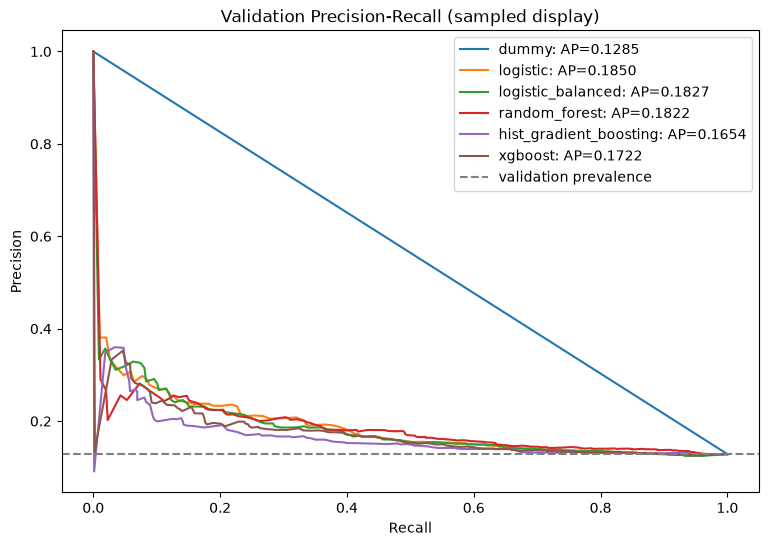

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
for name, curve in summary["display_curves"].items():
    ap = summary["results"][name]["metrics"]["average_precision"]
    ax.plot(curve["recall"], curve["precision"], label=f"{name}: AP={ap:.4f}")
ax.axhline(
    summary["selection"]["dummy_average_precision"],
    color="grey",
    linestyle="--",
    label="validation prevalence",
)
ax.set(xlabel="Recall", ylabel="Precision", title="Validation Precision-Recall (sampled display)")
ax.legend()
plt.show()

## Confusion matrices

Rows are actual classes; columns are predicted classes. Class 1 means `yes`. Compare missed subscribers and false positives at the same fixed threshold.

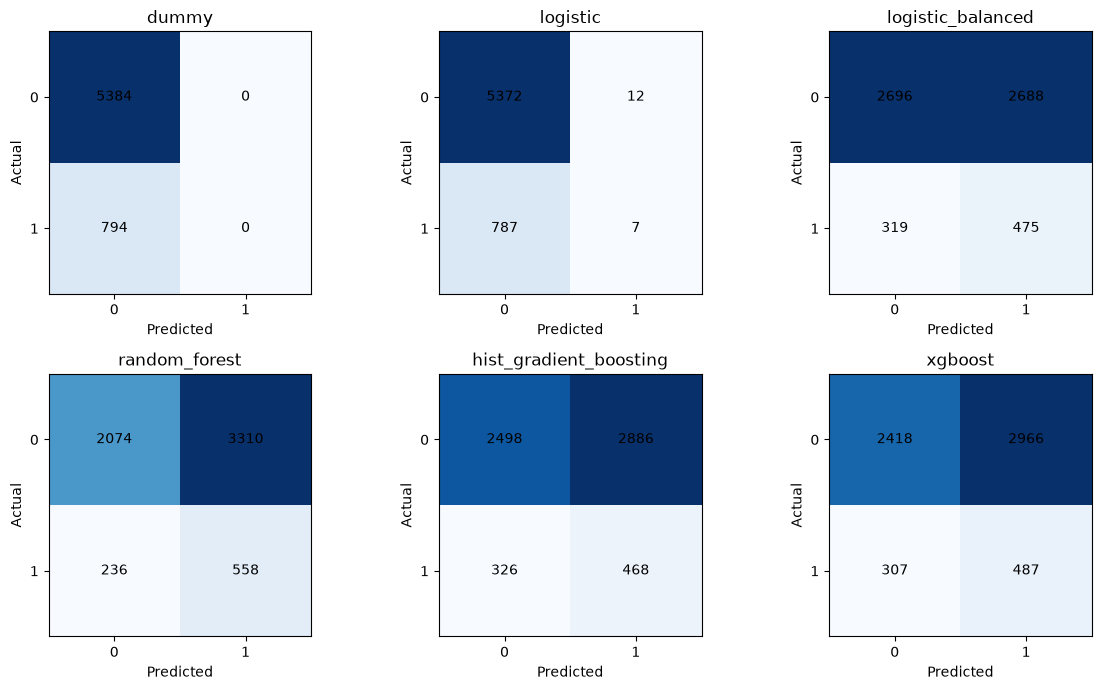

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (name, analysis) in zip(axes.flat, summary["error_analysis"].items(), strict=True):
    matrix = analysis["confusion_matrix"]
    ax.imshow(matrix, cmap="Blues")
    for row in range(2):
        for column in range(2):
            ax.text(column, row, str(matrix[row][column]), ha="center", va="center")
    ax.set(title=name, xlabel="Predicted", ylabel="Actual", xticks=[0, 1], yticks=[0, 1])
plt.tight_layout()
plt.show()

## Error and imbalance analysis

The following aggregates describe false negatives, false positives, previous-contact status and age groups. They contain no client rows. Small subgroups do not justify causal or fairness claims. No subgroup or validation error is used to tune the fixed parameters.

In [6]:
errors = []
for name, analysis in summary["error_analysis"].items():
    tn, fp = analysis["confusion_matrix"][0]
    fn, tp = analysis["confusion_matrix"][1]
    errors.append({"model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
display(pd.DataFrame(errors).set_index("model"))
winner = summary["selection"]["winner"]
if winner is not None:
    display(pd.DataFrame(summary["error_analysis"][winner]["subgroups"]).T)
    display(pd.DataFrame(summary["error_analysis"][winner]["probability_bins"]))

,TN,FP,FN,TP
model,,,,
dummy,5384,0,794,0
logistic,5372,12,787,7
logistic_balanced,2696,2688,319,475
random_forest,2074,3310,236,558
hist_gradient_boosting,2498,2886,326,468
xgboost,2418,2966,307,487


,support,positive_support,confusion_matrix
age_under_30,598,157,"[[439, 2], [157, 0]]"
age_30_to_59,5409,563,"[[4836, 10], [557, 6]]"
age_60_plus,171,74,"[[97, 0], [73, 1]]"
no_previous_contact,6049,739,"[[5310, 0], [739, 0]]"
previous_contact,129,55,"[[62, 12], [48, 7]]"


,lower,upper,support,observed_positive_rate
0,0.00,0.10,6120,0.126307
1,0.10,0.25,21,0.380952
2,0.25,0.50,18,0.333333
3,0.50,0.75,3,0.666667
4,0.75,1.00,16,0.312500


## Selection rationale

Choose the greatest validation AP strictly above Dummy, subject to recall no lower than ordinary Logistic Regression at 0.5. Exact ties follow the predeclared simpler-model order. This selects an experiment winner, without registry promotion or production deployment.

In [7]:
display(pd.Series(summary["selection"], name="recorded selection").to_frame())

,recorded selection
winner,logistic
eligible,"[logistic, logistic_balanced, random_forest, h..."
recall_floor,0.008816
dummy_average_precision,0.128521
threshold,0.5
primary_metric,average_precision
evaluation_split,validation
production_promoted,False


## Conclusions and limitations

Class weighting can improve recall while increasing false positives; AP evaluates ranking independently of the fixed decision threshold. Use the table and error counts to assess the recorded winner. Validation improvement is not a final-test result or evidence of production readiness.

All six candidates share one historical validation window. Repeated comparison, temporal shift, class imbalance, lack of client identifiers and the assumed availability of historical features limit generalization. Final test and replay remain reserved. Future registry, API and Microsoft RAG work is outside this experiment.